In [1]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import pytz

### Required File Paths

In [2]:
results_folder = 'results/6Mar2024_04_19' # store the results in this folder

capture_file_path = 'USRP_data/3_5/utctime_6Mar2024_04_19_33_freq_11_325G_bw_2.0M_ts_1709698773.3134246_inrx0.dat'
imu_file_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_04_19_12.txt'
tle_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_13_starlink.tle'
phase_comp_mat_path = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/6Mar2024_04_19/phase_comp.mat'

### Get Candidate Locations for our GS 
```get_candidate_locs``` returns candidate clusters or groups, their centroids (serve as coarse location of GS candidates) 
and the satellites associates with each cluster

In [3]:
start_time = datetime.fromtimestamp(float(capture_file_path.split('_')[-2]), tz=pytz.utc)
phase_comp_mat = sio.loadmat(phase_comp_mat_path)
tracked_peaks = phase_comp_mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
## time_arr.append(580.0)
# sort time_arr
time_arr = sorted(time_arr)
%matplotlib widget
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs
search_radius = 180 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs(start_time, time_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_file_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=15)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Candidate Ground Station Locations')
plt.show()

Initial number of candidate location clusters: 877
Possible: 77
Centroid of group  0 : [ 39.01225956 -88.34749753]
Point that minimizes distance to each satellite trajectory : 39.3468496456773 -88.39248410971068
sats in group: ['STARLINK-1080', 'STARLINK-30891', 'STARLINK-2052', 'STARLINK-4559', 'STARLINK-1090', 'STARLINK-5799', 'STARLINK-3501', 'STARLINK-4553']
Centroid of group  1 : [ 42.36958727 -86.78876868]
Point that minimizes distance to each satellite trajectory : 42.126412867329904 -88.15479420220441
sats in group: ['STARLINK-1237', 'STARLINK-1883', 'STARLINK-31385', 'STARLINK-30956', 'STARLINK-5782', 'STARLINK-30951', 'STARLINK-3902', 'STARLINK-6365']


/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:105: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Centroid of group  2 : [  39.61568614 -107.63211948]
Point that minimizes distance to each satellite trajectory : 39.84894125176831 -107.04539857440568
sats in group: ['STARLINK-1401', 'STARLINK-4423', 'STARLINK-1838', 'STARLINK-30039', 'STARLINK-3696', 'STARLINK-2105', 'STARLINK-1899', 'STARLINK-3691']
Centroid of group  3 : [  40.42280698 -102.08920752]
Point that minimizes distance to each satellite trajectory : 40.753357628188624 -100.613611306304
sats in group: ['STARLINK-1421', 'STARLINK-1437', 'STARLINK-31226', 'STARLINK-5769', 'STARLINK-1453', 'STARLINK-5784', 'STARLINK-5761', 'STARLINK-3172']
Centroid of group  4 : [  37.84192964 -106.07308529]
Point that minimizes distance to each satellite trajectory : 38.353612390870495 -104.71126648319888
sats in group: ['STARLINK-1437', 'STARLINK-5782', 'STARLINK-1453', 'STARLINK-30951', 'STARLINK-30521', 'STARLINK-3866', 'STARLINK-30869', 'STARLINK-3861']
Centroid of group  5 : [  45.53250946 -111.51193972]
Point that minimizes distance 

### Narrowing down to a single candidate GS location
- The idea is to compare the observed phase difference at our receiver/GS with the simulated phase differences at the candidate GS locations. 
- The best match results in a single candidate GS. 
- The satellites that are observed by this GS at time in time array will be the SAT IDs.

##### 1. Simulating to get phase difference for all satellites observed by all ground stations at times in time_arr

In [50]:
## Simulating to get phase differences 
## =================================================
from sat_id import faster_doppler_sim
import pickle
import os

filesavepath = os.path.join(results_folder,'satdictlist_for_each_gs.pkl') #TODO: change name/path if needed
load = True
# If kernel restarts or if satdictlist_for_each_gs.pkl is already, load it.
if load == True and os.path.exists(filesavepath):
    with open(filesavepath, 'rb') as f:
        satdictlist_for_each_gs = pickle.load(f)
else:
    # get satellite dopp dict for sats associated with each gs
    capture_start_timestamp = float(capture_file_path.split('_')[-2])
    print("start time: ", datetime.fromtimestamp(capture_start_timestamp, tz=pytz.utc))
    satdictlist_for_each_gs = [{} for i in range(len(coarse_gs))]

    #for each satellite at >75 degree min elevation wrt candidate gs, get the dopp, az, alt, range for about 10 secs around time in time_arr
    for gs_idx,cgs in enumerate(coarse_gs):
        for time in time_arr:
            # cgs = wgs84.latlon(cgs[0], cgs[1])
            # get sat dopp dict 
            date = '_'
            tle_path = tle_path
            fc = 11.325e9
            t_start = capture_start_timestamp + time - 5
            t_stop = capture_start_timestamp + time + 5
            t_step = 1
            gs = cgs
            # get sat dopp dict for this gs 
            sat_dopp_dict, _ = faster_doppler_sim(date, tle_path, fc, t_start, t_stop, t_step, gs, min_ele=75)
            satdictlist_for_each_gs[gs_idx][time] = sat_dopp_dict

    with open(filesavepath, 'wb') as f:
        pickle.dump(satdictlist_for_each_gs, f)

start time:  2024-03-06 04:19:33.313425+00:00
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  0
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  2
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  3
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  1
number of Starlink satellites loaded 5539
Duration in secs:  10.0
Number of visible satellites:  4
number of Starlink satellites loaded 5539
Duration in secs:  10

###### 

##### 2. From the simulated alt, az, etc. get the phase differences and the parameters fro each phase difference line (slope and intercept)

In [51]:
# get phase diff params or all sats in each group
from utils.satid_blind_identification import get_phase_diff_params_allsatsingroups
# orientation_dict = {'alpha':0,'beta':1.5,'gamma':1.6}
# print(orientation_dict)
phasediffdict_for_each_gs, phase_diff_param = get_phase_diff_params_allsatsingroups(coarse_gs, satdictlist_for_each_gs, time_arr, orientation_dict=orientation_dict)

{'alpha': 0, 'beta': 1.5, 'gamma': 1.6}
GS 0 Time 184.5725005
GS [ 39.01225956 -88.34749753] Time 184.5725005 Sat: STARLINK-1080
GS [ 39.01225956 -88.34749753] Time 184.5725005 Sat: STARLINK-30949
GS [ 39.01225956 -88.34749753] Time 184.5725005 Sat: STARLINK-2032
GS 0 Time 245.5600005
GS 0 Time 430.9935005
GS [ 39.01225956 -88.34749753] Time 430.9935005 Sat: STARLINK-3361
GS [ 39.01225956 -88.34749753] Time 430.9935005 Sat: STARLINK-2052
GS 0 Time 473.4870005
GS [ 39.01225956 -88.34749753] Time 473.4870005 Sat: STARLINK-2052
GS [ 39.01225956 -88.34749753] Time 473.4870005 Sat: STARLINK-4559
GS 0 Time 522.4485005
GS [ 39.01225956 -88.34749753] Time 522.4485005 Sat: STARLINK-1090
GS [ 39.01225956 -88.34749753] Time 522.4485005 Sat: STARLINK-3507
GS [ 39.01225956 -88.34749753] Time 522.4485005 Sat: STARLINK-2054
GS 0 Time 714.4410005
GS [ 39.01225956 -88.34749753] Time 714.4410005 Sat: STARLINK-5799
GS 0 Time 765.5970005
GS [ 39.01225956 -88.34749753] Time 765.5970005 Sat: STARLINK-3501
G

##### 3. Find the GS where the simulated phase difference parameters minimize the distance to the observed phase difference parameters

In [52]:
# find gs where the parameters minimize the difference with the observed phase diff
from utils.satid_blind_identification import find_best_coarse_gs
from utils.satid_blind_identification import get_observed_phase_diff_params
observed_phase_diff_params = get_observed_phase_diff_params(phase_comp_mat_path)
best_coarse_gs_candidate, best_candidate_idx, min_param_diff_pertime_each_gs, min_param_diff_sat_pertime_each_gs = find_best_coarse_gs(
                                                                                                coarse_gs, 
                                                                                                time_arr,
                                                                                                satdictlist_for_each_gs, 
                                                                                                phase_diff_param, 
                                                                                                observed_phase_diff_params)

No satellite found for GS: [ 39.01225956 -88.34749753]  at Time: 245.5600005
No satellite found for GS: [  39.61568614 -107.63211948]  at Time: 430.9935005
No satellite found for GS: [ 48.28285061 -83.93854924]  at Time: 473.4870005
No satellite found for GS: [ 42.33804801 -75.08392342]  at Time: 714.4410005
No satellite found for GS: [ 41.91574158 -85.17632304]  at Time: 765.5970005
No satellite found for GS: [ 43.81771012 -81.07268672]  at Time: 245.5600005
No satellite found for GS: [ 39.83267644 -99.93786052]  at Time: 522.4485005
No satellite found for GS: [  39.97983986 -107.89228757]  at Time: 430.9935005
No satellite found for GS: [  43.33030648 -102.35146892]  at Time: 522.4485005
No satellite found for GS: [ 39.02527396 -93.61097838]  at Time: 810.5160005
No satellite found for GS: [ 42.52569609 -90.54210499]  at Time: 714.4410005
No satellite found for GS: [ 43.08756003 -70.86391509]  at Time: 473.4870005
No satellite found for GS: [ 43.08756003 -70.86391509]  at Time: 765.5

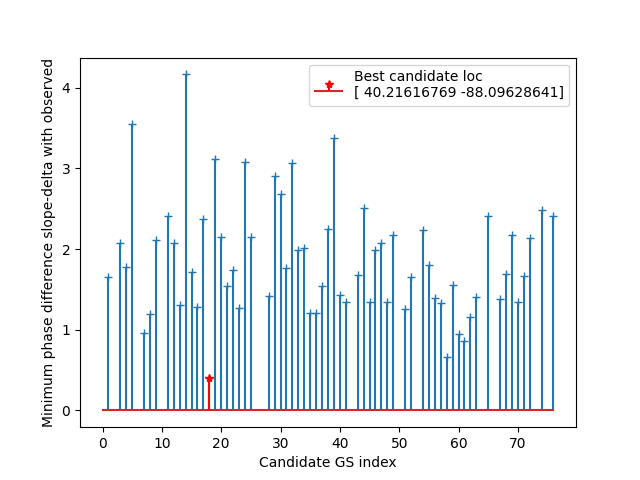

18

In [53]:
plt.figure()
plt.stem(range(len(coarse_gs)), np.sum(min_param_diff_pertime_each_gs, axis=1), markerfmt='+')
plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
plt.xlabel('Candidate GS index')
plt.ylabel('Minimum phase difference slope-delta with observed')
plt.legend()
plt.show()
best_candidate_idx

### Save data needed for localization

In [54]:
save_dict = {}
save_dict['real_gs'] = lat_lon_alt_mean
save_dict['centroid_gs'] = best_coarse_gs_candidate
save_dict['search_radius'] = search_radius
# get farthest gs in the candidate gs_group

from utils.helper import get_distkm_latlon_coordinates

loc1 = lat_lon_alt_mean[:2]
loc2 = gs_groups[best_candidate_idx]
dists = get_distkm_latlon_coordinates(loc1, loc2)
farthest_gs_idx = np.argmax(dists)
farthest_gs = gs_groups[best_candidate_idx][farthest_gs_idx]
d1 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d2 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (lat_lon_alt_mean[0], farthest_gs[1]))
d3 = search_radius + get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))
d4 = search_radius - get_distkm_latlon_coordinates(lat_lon_alt_mean[:2], (farthest_gs[0], lat_lon_alt_mean[1]))

save_dict['farthest_gs'] = farthest_gs
save_dict['d1'] = d1 # distance to left/west boundary
save_dict['d2'] = d2 # distance to right/east boundary
save_dict['d3'] = d3 # distance to top/north boundary
save_dict['d4'] = d4 # distance to bottom/south boundary
print('d1: ', d1, 'd2: ', d2, 'd3: ', d3, 'd4: ', d4)
sio.savemat(os.path.join(results_folder,'coarsegs_search.mat'), save_dict) #TODO: change name/path if needed

d1:  [142.23597828] d2:  [217.76402172] d3:  [301.43240059] d4:  [58.56759941]


### Save output_doppler_coarsegs.mat generated with the coarse_gs location

In [55]:
from sat_id import faster_doppler_sim
import os 

date = results_folder.split('/')[-1]
print(date)
if not os.path.exists(os.path.join(results_folder, "info.mat")):
    print("Run Starloc.ipynb first to get info.mat")
fc = 11.325e9
sim_start_time = float(capture_file_path.split('_')[-2])
t_end = sio.loadmat(os.path.join(results_folder, "info.mat"))['t_end'][0][0]
lat_gt, lon_gt = best_coarse_gs_candidate
sim_end_time = sim_start_time+t_end
# sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
sat_dopp_dict, t_list = faster_doppler_sim(date, tle_path, fc, sim_start_time, sim_end_time, 1, ground_station=(lat_gt, lon_gt))
output_doppler_file = os.path.join(results_folder,"output_doppler_coarsegs.mat")
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

6Mar2024_04_19
number of Starlink satellites loaded 5539
Duration in secs:  878.7466878890991


KeyboardInterrupt: 